In [2]:
%pip install plotly

Note: you may need to restart the kernel to use updated packages.


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

BOX = "/Users/shawnlam/Library/CloudStorage/Box-Box/Chicago Rat Project/"
## Path to the rodent baiting spreadsheet
RAT = "/Users/shawnlam/Everything GRAD/Literature/Class/Rodent_Baiting_-_Historical_20261106.xlsx"

In [3]:
rat = pd.read_excel(RAT)
## Remember the starting row count so we can report removals
n0 = len(rat)
## Print how many rows we started with
print(f"Start: {n0:,} rows")
## Drop unneeded columns 
drop_cols = ["Street Address", "X Coordinate", "Y Coordinate", "Location",
             "Ward", "Community Area", "Current Activity", "Type of Service Request"]
rat = rat.drop(columns=drop_cols, errors="ignore")
## Remove duplicates
is_dup = rat["Status"].str.contains("Dup", na=False)
## Count the duplicates being removed
n_dup = int(is_dup.sum())
## Keep only the non-duplicate rows (Completed and Open stay)
rat = rat[~is_dup].copy()
## Report the removal
print(f"Removed duplicates: {n_dup:,} rows")


Start: 319,187 rows
Removed duplicates: 20,751 rows


In [4]:
## The ZIP (our join key) and the three count columns are required for the analysis
needed = ["ZIP Code", "Number of Premises Baited",
          "Number of Premises with Garbage", "Number of Premises with Rats"]
## Remember the count before dropping
before = len(rat)
## Drop rows where any required column is missing (other columns are irrelevant here)
rat = rat.dropna(subset=needed).copy()
## Report the removal
print(f"Removed rows with missing ZIP/counts: {before - len(rat):,} rows")

Removed rows with missing ZIP/counts: 4,711 rows


In [5]:
## remove outliers 
count_cols = needed[1:]
## Compute the 99.9th percentile of each count column as the upper cutoff
caps = rat[count_cols].quantile(0.999)
## Print the cutoffs so they are transparent
print("Outlier cutoffs (99.9th percentile):\n", caps.to_string())
## A row is an outlier if ANY count exceeds its column's cutoff
is_out = (rat[count_cols] > caps).any(axis=1)
## Count outliers
n_out = int(is_out.sum())
## Drop them
rat = rat[~is_out].copy()
## Report the removal
print(f"Removed outliers: {n_out:,} rows")
## Report the final row count and total removed
print(f"Final: {len(rat):,} rows (removed {n0 - len(rat):,} of {n0:,} in total)")

Outlier cutoffs (99.9th percentile):
 Number of Premises Baited          15.0
Number of Premises with Garbage    21.0
Number of Premises with Rats       19.0
Removed outliers: 763 rows
Final: 292,962 rows (removed 26,225 of 319,187 in total)


In [6]:
## ZIPs were read as floats (60601.0); convert to a 5-character string like "60601"
rat["zip"] = rat["ZIP Code"].astype(int).astype(str).str.zfill(5)
## Group by ZIP, count requests, and total each premises column SEPARATELY (never added together)
by_zip = rat.groupby("zip").agg(
    ## Number of rows = number of complaints (service requests) in the ZIP
    complaints=("Service Request Number", "count"),
    ## Total premises baited in the ZIP
    premises_baited=("Number of Premises Baited", "sum"),
    ## Total premises with garbage in the ZIP
    premises_garbage=("Number of Premises with Garbage", "sum"),
    ## Total premises with rats in the ZIP
    premises_rats=("Number of Premises with Rats", "sum"),
    ## Turn the grouped index back into a normal "zip" column
).reset_index()

In [7]:
## Read median/mean income, keeping ZIP as text so it matches
inc = pd.read_csv(BOX + "chicago_mean_median_income_by_zip.csv", dtype={"zip": str})
## Read the bracket data (only ZIP, total households, and the lowest brackets for a low-income share)
br = pd.read_csv(BOX + "chicago_income_brackets_by_zip.csv", dtype={"zip": str})
## Share of households under $35k = sum of the first six brackets / total
br["pct_under_35k"] = br[["<10k", "10-15k", "15-20k", "20-25k", "25-30k", "30-35k"]].sum(axis=1) / br["Total"] * 100
## Keep only the columns we need from the bracket file
br = br[["zip", "pct_under_35k"]]
## Join rodent totals with income, keeping only ZIPs found in both
df = by_zip.merge(inc, on="zip", how="inner").merge(br, on="zip", how="inner")
## Report ZIPs that did not match, so nothing disappears silently
print("ZIPs in rodent data but not income data:", sorted(set(by_zip.zip) - set(df.zip)))

## Measures to convert to rates
measures = ["complaints", "premises_baited", "premises_garbage", "premises_rats"]
## For each measure, divide by households and multiply by 1,000
for m in measures:
    ## New column named e.g. complaints_per_1000
    df[m + "_per_1000"] = df[m] / df["households"] * 1000
## Drop ZIPs with no median income estimate (suppressed by the Census)
df = df.dropna(subset=["median_household_income"])
## Save the merged analysis table
df.to_csv("zip_analysis_table.csv", index=False)



ZIPs in rodent data but not income data: ['00000', '60635', '60666', '60707', '60827']


In [8]:
## Map each ZIP to its main neighborhood(s). Written from general knowledge: ZIPs span several neighborhoods, so please check these.
hood = {
    "60601": "Loop / New Eastside", "60602": "Loop", "60603": "Loop", "60604": "Loop",
    "60605": "South Loop", "60606": "West Loop", "60607": "University Village", "60608": "Pilsen / Bridgeport",
    "60609": "Back of the Yards", "60610": "Old Town", "60611": "Streeterville", "60612": "Near West Side",
    "60613": "Lakeview / Uptown", "60614": "Lincoln Park", "60615": "Hyde Park/Kenwood", "60616": "Bronzeville / Chinatown",
    "60617": "South Chicago", "60618": "North Center", "60619": "Chatham", "60620": "Auburn Gresham",
    "60621": "Englewood", "60622": "Wicker Park", "60623": "Little Village", "60624": "Garfield Park",
    "60625": "Lincoln Square", "60626": "Rogers Park", "60628": "Roseland", "60629": "Chicago Lawn",
    "60630": "Jefferson Park", "60631": "Edison Park", "60632": "Brighton Park", "60633": "Hegewisch",
    "60634": "Dunning", "60636": "West Englewood", "60637": "Hyde Park/Woodlawn", "60638": "Garfield Ridge",
    "60639": "Belmont Cragin", "60640": "Uptown", "60641": "Portage Park", "60642": "River West",
    "60643": "Morgan Park", "60644": "Austin", "60645": "West Ridge", "60646": "Sauganash",
    "60647": "Logan Square", "60649": "South Shore", "60651": "Humboldt Park", "60652": "Ashburn",
    "60653": "Oakland / Kenwood", "60654": "River North", "60655": "Mount Greenwood", "60656": "Norwood Park",
    "60657": "Lakeview", "60659": "North Park", "60660": "Edgewater", "60661": "Fulton Market",
}
## Add the neighborhood name as a column, falling back to the ZIP if one is missing
df["neighborhood"] = df["zip"].map(hood).fillna(df["zip"])

/var/folders/j0/sl7bmld10t96v3ph0p1jdf2w0000gn/T/ipykernel_6910/1860043037.py:46: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout(rect=[1, 0.08, 1, 0.08])


                         complaints_per_1000  premises_baited_per_1000  \
median_household_income                -0.30                     -0.29   
mean_household_income                  -0.29                     -0.30   
pct_under_35k                           0.23                      0.24   

                         premises_garbage_per_1000  premises_rats_per_1000  
median_household_income                      -0.41                   -0.34  
mean_household_income                        -0.42                   -0.35  
pct_under_35k                                 0.38                    0.30  


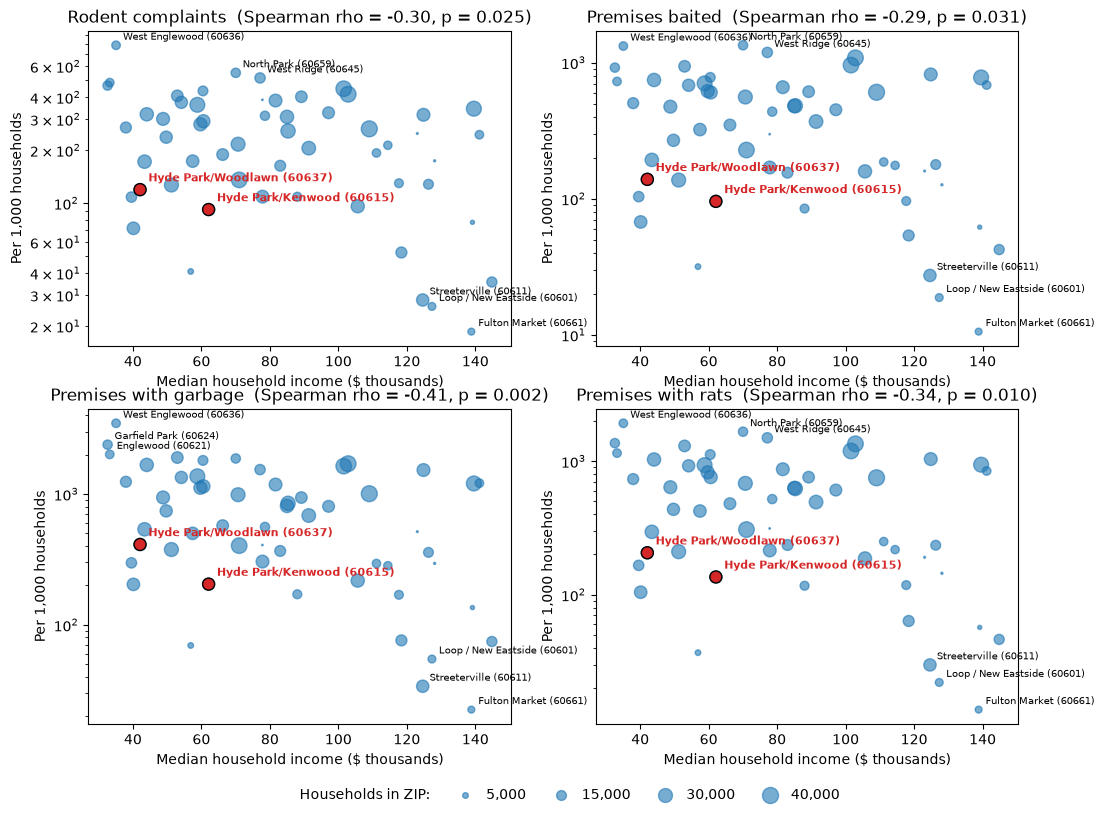

In [9]:
## Titles for the four panels
titles = {"complaints_per_1000": "Rodent complaints",
          "premises_baited_per_1000": "Premises baited",
          "premises_garbage_per_1000": "Premises with garbage",
          "premises_rats_per_1000": "Premises with rats"}
## Create a 2x2 grid of panels
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

## Loop over each panel and its measure
for ax, (col, title) in zip(axes.ravel(), titles.items()):
    ## Draw one point per ZIP, sized by household count so small noisy ZIPs look small
    ax.scatter(df["median_household_income"] / 1000, df[col], s=df["households"] / 300, alpha=0.6)
    ## Find the 3 ZIPs with the highest and 3 with the lowest rate in this panel
    extremes = pd.concat([df.nlargest(3, col), df.nsmallest(3, col)])
    ## Label each extreme point with its neighborhood name and ZIP
    for _, r in extremes.iterrows():
        ## Place the text slightly up and to the right of the point so it doesn't cover it
        ax.annotate(f"{r['neighborhood']} ({r['zip']})", (r["median_household_income"] / 1000, r[col]),
                    textcoords="offset points", xytext=(5, 4), fontsize=7)
    ## Pick out the Hyde Park ZIPs
    hp = df[df["zip"].isin(["60615", "60637"])]
    ## Redraw those points on top in a contrasting color with a dark edge so they stand out
    ax.scatter(hp["median_household_income"] / 1000, hp[col], s=hp["households"] / 300, color="tab:red", edgecolor="black", zorder=3)
    ## Label each Hyde Park point in bold red
    for _, r in hp.iterrows():
        ## Offset the text up and to the right so it doesn't cover the point
        ax.annotate(f"{r['neighborhood']} ({r['zip']})", (r["median_household_income"] / 1000, r[col]),
                    textcoords="offset points", xytext=(6, 6), fontsize=8, fontweight="bold", color="tab:red")
    ## Compute the Spearman correlation and p-value for this pair
    rho, p = spearmanr(df["median_household_income"], df[col])
    ## Show the correlation in the panel title
    ax.set_title(f"{title}  (Spearman rho = {rho:.2f}, p = {p:.3f})")
    ## Label the x axis
    ax.set_xlabel("Median household income ($ thousands)")
    ## Label the y axis
    ax.set_ylabel("Per 1,000 households")
    ## Counts are skewed, so use a log y axis
    ax.set_yscale("log")
legend_sizes = [5000, 15000, 30000, 40000]
## An invisible dummy entry whose label acts as the title, so it appears on the left of the row
title_handle = plt.Line2D([], [], linestyle="none", label="Households in ZIP:")
## One empty scatter point per size, scaled exactly like the real points (households / 300)
size_handles = [plt.scatter([], [], s=h / 300, alpha=0.6, color="tab:blue", label=f"{h:,}") for h in legend_sizes]
## Draw one legend row along the bottom, with the title entry first and no space reserved for its marker
fig.legend(handles=[title_handle] + size_handles, loc="lower center", ncol=len(legend_sizes) + 1, frameon=False, labelspacing=1.5, borderpad=1.2, handletextpad=0.5, columnspacing=1.5)
plt.tight_layout(rect=[1, 0.08, 1, 0.08])

## Print the correlations as a small table
print(df[["median_household_income", "mean_household_income", "pct_under_35k"] + [m + "_per_1000" for m in measures]].corr(method="spearman").round(2).iloc[:3, 3:])


In [10]:
%matplotlib inline

In [14]:
## Import plotly's graph objects for fine control over hover text
import plotly.graph_objects as go
## Import the helper that builds a grid of subplots
from plotly.subplots import make_subplots
## Import Spearman correlation for the panel titles
from scipy.stats import spearmanr

## The four measures: (column name, display title)
panels = [("complaints", "Rodent complaints"), ("premises_baited", "Premises baited"),
          ("premises_garbage", "Premises with garbage"), ("premises_rats", "Premises with rats")]
## Build a title for each panel that includes its Spearman correlation
titles = []
## Loop over the measures
for m, t in panels:
    ## Compute the correlation and p-value between median income and this per-1,000 rate
    rho, p = spearmanr(df["median_household_income"], df[m + "_per_1000"])
    ## Add the formatted title
    titles.append(f"{t} (Spearman rho = {rho:.2f}, p = {p:.3f})")
## Create a 2x2 grid of panels with those titles
fig = make_subplots(rows=2, cols=2, subplot_titles=titles, vertical_spacing=0.14)
## Flag the Hyde Park ZIPs so they can be highlighted
hp = df["zip"].isin(["60615", "60637"])
## Loop over the panels, numbering them 0-3
for i, (m, t) in enumerate(panels):
    ## Convert the panel number to a row and column in the 2x2 grid
    r, c = divmod(i, 2)
    ## Bundle the values shown on hover: neighborhood, ZIP, households, raw total, median income
    custom = df[["neighborhood", "zip", "households", m, "median_household_income"]].to_numpy()
    ## Add one scatter trace, with one point per ZIP, to this panel
    fig.add_trace(go.Scatter(
        ## x is median income in thousands of dollars
        x=df["median_household_income"] / 1000,
        ## y is the rate per 1,000 households
        y=df[m + "_per_1000"],
        ## Draw markers only (no connecting lines)
        mode="markers",
        ## Marker size grows with household count, Hyde Park is red with a black outline, others blue
        marker=dict(size=df["households"] / 1500 + 5, color=["crimson" if h else "steelblue" for h in hp],
                    opacity=0.7, line=dict(width=[2 if h else 0 for h in hp], color="black")),
        ## Attach the extra values so the hover text can use them
        customdata=custom,
        ## The text shown when the mouse is over a point
        hovertemplate=("<b>%{customdata[0]} (%{customdata[1]})</b><br>"
                       "Median income: $%{customdata[4]:,.0f}<br>"
                       + t + " per 1,000 households: %{y:,.1f}<br>"
                       + "Total " + t.lower() + ": %{customdata[3]:,.0f}<br>"
                       + "Households: %{customdata[2]:,.0f}<extra></extra>"),
        ## No legend entry for this trace
        showlegend=False), row=r + 1, col=c + 1)
    ## Label this panel's x axis
    fig.update_xaxes(title_text="Median household income ($ thousands)", row=r + 1, col=c + 1)
    ## Label this panel's y axis and use a log scale because the rates are skewed
    fig.update_yaxes(title_text="Per 1,000 households", type="log", row=r + 1, col=c + 1)
## Set the overall figure size and a clean white theme
fig.update_layout(height=800, width=1100, template="simple_white")
## Display the interactive figure in the notebook
fig.show()